#### CatBoost v2: agriculture population, with rel/attsch/occ added

Same as `train-catboost_v2_agri.ipynb` (population, wage formula, toggles), with three extra features added to test whether they help: `rel`, `attsch`, `occ`.

<div style="font-size: 10pt;">

What this notebook implements from the email:

- Zero-income (unpaid) respondents: included.
- Hours worked and second-job hours: included for the male model only.
- Employment status (`emps`): excluded. The with_emps diagnostic notebook showed that once zero income is included, this one variable drives 81% of female feature importance on its own, since unpaid family workers are coded there by definition.
- Employment stability (`empstab`): the email asked to include it. We found it correlates 0.73 with paid status within agriculture (regular work is mostly unpaid family labor, seasonal work is mostly hired paid labor), close to the same circularity as `emps`. Checked against the official HLFS data dictionary: both variables are correctly identified, so this is a real tradeoff, not a mix-up. It is now a setting (`INCLUDE_EMPSTAB`, Section 0b) so both versions can be compared directly.

Extra features tested here, the same three as `train-catboost_raw_with_zeros.ipynb`: `rel` (relationship to household head) and `attsch` (school attendance) correlate with male zero-wage status at 0.27 and 0.26, real signal rather than wage-derived. `occ` (occupation code) is a structural job characteristic, same category as employment stability. None are in the `correlation.xlsx` mask, so they were not in `train-catboost_v2_agri.ipynb`'s feature set. Added directly in Section 7, with the same categorical treatment as the reference notebook.

Production data note: uses the `command_unit` sheet directly, already scaled, no normalization needed.

Open items:

- Hyperparameter tuning: not yet done.
- Compare results against `train-catboost_v2_agri.ipynb` once both have a full run.

</div>

In [ ]:
from egypt_survey_ml import (
    apply_zero_handling,
    assign_command_units,
    attach_governorate,
    attach_household_context,
    build_feature_frame,
    build_household_features,
    build_wage_target,
    convert_irregular,
    drop_random_zeros,
    evaluate,
    evaluate_participation,
    filter_rural_agriculture_population,
    fit_and_predict,
    fit_and_predict_classifier,
    gender_gap,
    lognormal_synthetic_augment,
    perturbate_wage,
    run_once,
    run_once_classifier,
    split_train_test,
)
from egypt_survey_ml.catboost import LAST_MODELS, LAST_MODELS_CLASSIFIER


In [1]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
)
from scipy import stats as sstats
from catboost import CatBoostRegressor, CatBoostClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

RNG_SEED = 42
MIN_WORKING_AGE = 15
WEEKS_PER_MONTH = 365.25 / 7 / 12  # ~4.348


#### 0b. Settings: edit here, then re-run from Section 7

<div style="font-size: 10pt;">

Sections 1 to 6 (data loading, population, `command_unit` data) do not depend on these settings and do not need to be re-run. After changing a setting here, re-run: this cell, then Section 7, then Section 10 (point estimate, SHAP, comparison log). Re-run Section 11 only when you want the full repeated-evaluation result for that configuration.

</div>

In [2]:
# --- toggles -----------------------------------------------------------
INCLUDE_EMPSTAB = True   # see design-decisions table above: circular under the zero-inclusive regime
INCLUDE_HRSWK_FEMALE = True  # team decision (Vanni's email) excludes hours for the female model;
                              # the audit branch's train-catboost_raw*.ipynb notebooks all keep it
                              # for female too. Toggle this to test how much of their higher
                              # reported R2 comes from that one feature, holding everything else
                              # (repeated eval, intensive-margin decomposition, wage formula, cap)
                              # fixed at our more rigorous setup.
ZERO_HANDLING = "drop_random"    # one of: "none", "drop_random", "lognormal_synthetic"
PREDICT_LOG_WAGE = False
WAGE_PERTURBATION = False
INCLUDE_RIBASIM = False
WAGE_PERTURBATION_SIGMA = 0.03
DROP_RANDOM_FRAC = 1.0    # only used when ZERO_HANDLING == "drop_random"
N_REPS = 100               # change this


#### 1. Data location

<div style="font-size: 10pt;">

Uses the local copy under `ERF_Data/Data` if present, OneDrive otherwise.

</div>

In [3]:
REPO_ROOT = Path.cwd().parent
LOCAL_DATA_ROOT = Path(os.environ.get("EGYPT_DATA_ROOT", REPO_ROOT / "ERF_Data" / "Data"))

_onedrive_home = Path("~").expanduser()

_egypt_candidates = [
    _onedrive_home / "OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt",
]

_erf_candidates = [
    _onedrive_home / "OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt_ERF_data",
]

egypt_root = next((p for p in _egypt_candidates if p.exists()), None)
erf_root = next((p for p in _erf_candidates if p.exists()), None)

if (LOCAL_DATA_ROOT / "data_correlation.xlsx").exists():
    DATA_ROOT = LOCAL_DATA_ROOT
    EXCEL_PATH = DATA_ROOT / "data_correlation.xlsx"
    CROSSWALK_CSV = DATA_ROOT / "crosswalk" / "reg_governorate_crosswalk.csv"
    COMMAND_AREA_CROSSWALK_CSV = DATA_ROOT / "crosswalk" / "command_area_governorate_crosswalk.csv"
    print(f"data source: local ({DATA_ROOT})")
else:
    if egypt_root is None or erf_root is None:
        raise FileNotFoundError(
            "Could not find required OneDrive folders."
        )

    DATA_ROOT = egypt_root / "04_Data/2026_data"
    EXCEL_PATH = erf_root / "data_correlation.xlsx"
    CROSSWALK_CSV = DATA_ROOT.parent / "cleaned_data/crosswalk" / "reg_governorate_crosswalk.csv"
    COMMAND_AREA_CROSSWALK_CSV = DATA_ROOT.parent / "cleaned_data/crosswalk" / "command_area_governorate_crosswalk.csv"
    # print(f"data source: OneDrive fallback ({_onedrive_root})")

LFS_DTA = DATA_ROOT / "Labor Force Survey, LFS 2022 - Egypt, Arab Rep., 2022" / "Egypt 2022-LFS IND-V1.dta"
HH_DTA = DATA_ROOT / "Labor Force Survey, LFS 2022 - Egypt, Arab Rep., 2022" / "Egypt 2022-LFS HH-V1.dta"
RESULT_DIR = DATA_ROOT.parent / "Result"
MASK_XLSX = RESULT_DIR / "correlation.xlsx"
POP_DENSITY_CSV = RESULT_DIR / "population_density_matrix.csv"

for p in [LFS_DTA, HH_DTA, CROSSWALK_CSV, COMMAND_AREA_CROSSWALK_CSV, MASK_XLSX, POP_DENSITY_CSV, EXCEL_PATH]:
    print(("OK  " if p.exists() else "MISSING "), p)


OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/2026_data/Labor Force Survey, LFS 2022 - Egypt, Arab Rep., 2022/Egypt 2022-LFS IND-V1.dta
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/2026_data/Labor Force Survey, LFS 2022 - Egypt, Arab Rep., 2022/Egypt 2022-LFS HH-V1.dta
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/cleaned_data/crosswalk/reg_governorate_crosswalk.csv
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/cleaned_data/crosswalk/command_area_governorate_crosswalk.csv
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/Result/correlation.xlsx
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt/04_Data/Result/population_density_matrix.csv
OK   /Users/hemert/OneDrive - Stichting Deltares/Tiaravanni Hermawan's files - Egypt_ER

#### 2. Load survey data, build household features

<div style="font-size: 10pt;">

Same logic as `01_preprocess_lfs2022_individual.ipynb`: household size, number of other employed household members, household head info, and household wage total, with irregular wages converted to monthly using each person's own hours.

</div>

In [ ]:
household_size, n_employed_in_hh, head_info, hh_wage = build_household_features(df, hh)
print("household_wage_total / wage_ratio computed for", len(hh_wage), "rural households")


individual shape: (299423, 106)  household shape: (76976, 116)
household_wage_total / wage_ratio computed for 45426 rural households


#### 3. Population: rural and agriculture, for training and test

<div style="font-size: 10pt;">

Same filter as `train-catboost.ipynb`: age 15+, rural, employed, agriculture industry only, no other industry included. The test set is set aside first, before any modeling, so training never sees a test row.

</div>

In [ ]:
agri_pool = filter_rural_agriculture_population(
    df,
    min_working_age=MIN_WORKING_AGE,
    industry_code=10,
)
print(f"Rural + agriculture population: {len(agri_pool)} rows "
      f"({(agri_pool['sex']==1).sum()} male, {(agri_pool['sex']==2).sum()} female)")

train_pool, test_pool, TEST_IDS = split_train_test(
    agri_pool,
    seed=RNG_SEED,
    test_size=0.2,
)

assert TEST_IDS.isdisjoint(set(train_pool.index)), "test/train overlap -- must never happen"
print(f"\nTEST (rural + agriculture): {len(test_pool)} rows "
      f"({(test_pool['sex']==1).sum()} male, {(test_pool['sex']==2).sum()} female)")
print(f"TRAIN (rural + agriculture, test rows excluded): {len(train_pool)} rows "
      f"({(train_pool['sex']==1).sum()} male, {(train_pool['sex']==2).sum()} female)")


Dropped 100476 under age 15. Rural, working-age, employed: 46027 rows (39700 male, 6327 female)
Rural + agriculture population: 14043 rows (12019 male, 2024 female)

TEST (rural + agriculture): 2809 rows (2404 male, 405 female)
TRAIN (rural + agriculture, test rows excluded): 11234 rows (9615 male, 1619 female)


#### 4. Household features and wage target

In [ ]:
# Shared household and wage-target helpers are imported from egypt_survey_ml.

train_pool = build_wage_target(attach_household_context(train_pool))
test_pool = build_wage_target(attach_household_context(test_pool))
survey_columns = train_pool.columns

print(f"TRAIN: {len(train_pool)} rows, {train_pool['is_paid'].mean():.1%} paid overall "
      f"(male {train_pool.loc[train_pool['sex']==1,'is_paid'].mean():.1%}, "
      f"female {train_pool.loc[train_pool['sex']==2,'is_paid'].mean():.1%})")
print(f"TEST  (rural+agri only): {len(test_pool)} rows, {test_pool['is_paid'].mean():.1%} paid overall "
      f"(male {test_pool.loc[test_pool['sex']==1,'is_paid'].mean():.1%}, "
      f"female {test_pool.loc[test_pool['sex']==2,'is_paid'].mean():.1%})")


  dropped 232 rows missing mart_d
  dropped 19 rows with totwag_all >= 10,000 EGP (outlier cap)
  dropped 73 rows missing mart_d
  dropped 4 rows with totwag_all >= 10,000 EGP (outlier cap)
TRAIN: 10951 rows, 81.1% paid overall (male 91.1%, female 22.4%)
TEST  (rural+agri only): 2727 rows, 81.8% paid overall (male 91.7%, female 24.6%)


#### 5. Governorate and command-unit assignment

<div style="font-size: 10pt;">

Each respondent's command area is drawn at random from the governorate-level population distribution. Done as a function so Section 11 can repeat it with a fresh draw each time, while train and test membership stay fixed.

</div>

In [ ]:
crosswalk = pd.read_csv(CROSSWALK_CSV)
distribution_df = pd.read_csv(POP_DENSITY_CSV, index_col="NAME1_")

train_pool = attach_governorate(train_pool)
test_pool = attach_governorate(test_pool)


#### 6. Production and command-unit data from `command_unit`

<div style="font-size: 10pt;">

Uses the `command_unit` sheet directly. 

</div>

In [8]:
excel_df = pd.read_excel(EXCEL_PATH, sheet_name="command_unit")
print(f"Loaded command_unit: {excel_df.shape[0]} areas, {excel_df.shape[1]} columns "
      f"(already scaled -- no rural-population normalization needed for this sheet)")


Loaded command_unit: 60 areas, 75 columns (already scaled -- no rural-population normalization needed for this sheet)


#### 7. Feature set

<div style="font-size: 10pt;">

From the `correlation.xlsx` mask, plus the team's decisions: hours worked for the male model always, for the female model only if `INCLUDE_HRSWK_FEMALE` is set. Employment stability follows `INCLUDE_EMPSTAB`. Employment status is always excluded, confirmed circular once zero income is included. Both settings live in Section 0b.

Also adds `rel`, `attsch` and `occ`, none of which are in the mask file. Treated as categorical, same as `train-catboost_raw_with_zeros.ipynb`.

</div>

In [9]:
masking_df = pd.read_excel(MASK_XLSX, sheet_name="Sheet1")
base_cols = masking_df.loc[masking_df["correl"] == 1, "variable"].tolist()
# hrswk/hrswksc are handled separately below regardless of whether the mask file also lists
# them -- stripped here so they can never end up duplicated in the feature list.
base_cols = [c for c in base_cols if c not in ("emps", "hrswk", "hrswksc", "totwag")]
if not INCLUDE_EMPSTAB:
    base_cols = [c for c in base_cols if c != "empstab"]

# rel, attsch, occ aren't in the mask file (correl==0 there), so they were never in
# train-catboost_v2_agri.ipynb's feature set. Added here the same way as
# train-catboost_raw_with_zeros.ipynb: rel (relationship to household head) and attsch
# (school attendance) correlate with male zero-wage status at 0.27 and 0.26 -- real signal,
# not wage-derived. occ (occupation code) is a structural job characteristic, same category
# as empstab. Applied to both sexes, not gender-specific like hrswk.
EXTRA_FEATURES = [c for c in ["rel", "attsch", "occ"] if c in agri_pool.columns]
base_cols = base_cols + [c for c in EXTRA_FEATURES if c not in base_cols]

MALE_EXTRA = ["hrswk", "hrswksc"]
FEMALE_EXTRA = ["hrswk", "hrswksc"] if INCLUDE_HRSWK_FEMALE else []

# MALE_EXTRA = []
# FEMALE_EXTRA = [] if INCLUDE_HRSWK_FEMALE else []

categorical_columns = masking_df[
    (masking_df["type"].isin(["binary", "categorical"])) & (masking_df["variable"].isin(base_cols))
]["variable"].tolist()
# rel, attsch, occ are nominal codes, not ordered numbers, and the mask file lists their type
# as "-" so the filter above never picks them up -- added explicitly.
categorical_columns = categorical_columns + [c for c in EXTRA_FEATURES if c not in categorical_columns]

print(f"Base feature list: {len(base_cols)} columns")
print(f"Categorical: {categorical_columns}")
print(f"INCLUDE_EMPSTAB={INCLUDE_EMPSTAB}  INCLUDE_HRSWK_FEMALE={INCLUDE_HRSWK_FEMALE}  ZERO_HANDLING={ZERO_HANDLING!r}")


Base feature list: 62 columns
Categorical: ['sex', 'mart_d', 'rel', 'immigr', 'disabl', 'lit', 'attsch', 'empstab', 'hlthins', 'socsec', 'occ']
INCLUDE_EMPSTAB=True  INCLUDE_HRSWK_FEMALE=True  ZERO_HANDLING='drop_random'


#### 8. Zero-income handling

<div style="font-size: 10pt;">

Two options, applied to the training data only: randomly drop a share of zero-wage rows, or generate synthetic paid rows for the female model assuming a log-normal wage distribution, as requested.

</div>

In [ ]:
GEO_COLS = ["command_unit"] + [c for c in excel_df.columns if c != "area"]


#### 9. Metrics

<div style="font-size: 10pt;">

MAE, RMSE and R2 on the full target, plus the same metrics restricted to paid respondents only. The two can disagree substantially when most of the population is unpaid, so both are reported.

</div>

In [ ]:
# Shared performance and gap helpers are imported from egypt_survey_ml.


#### 10. Single run at the current settings

<div style="font-size: 10pt;">

One train and test split, used as a quick check and to log the current settings into the comparison chart in Section 10c.

</div>

In [ ]:
# Shared feature-building, zero-handling, training, and evaluation helpers are imported from egypt_survey_ml.
# The package tracks LAST_MODELS / LAST_MODELS_CLASSIFIER in its own module globals, and we mirror
# those exported dictionaries here so the SHAP cells continue to work without local redefinitions.
LAST_MODELS.clear()
LAST_MODELS_CLASSIFIER.clear()

# Comparison log: persists across re-runs of THIS cell (guarded), so toggling a setting and
# re-running Section 7 + this cell repeatedly accumulates one row per gender per
# configuration tried, instead of overwriting the previous result. Re-run just this "if"
# line yourself (or restart the kernel) if you deliberately want to clear it.
if "comparison_log" not in globals():
    comparison_log = []

_results, _gap, _ = run_once(RNG_SEED)
print(pd.DataFrame(_results).T)
print()
print("Gender gap (EGP/month), predicted vs. observed:", _gap)

_config_label = f"EMPSTAB={INCLUDE_EMPSTAB}, HRSWK_F={INCLUDE_HRSWK_FEMALE}, ZERO={ZERO_HANDLING!r}"
for _sex_label, _m in _results.items():
    comparison_log.append({"config": _config_label, **_m})
print(f"\nLogged this run as {_config_label!r} -- comparison_log has {len(comparison_log)} rows "
      f"({len(comparison_log)//2} configurations tried this session). See Section 10c to visualize."
      )


         label     n         mae        rmse        r2  spearman mean_pred_at_true_zero mean_pred_at_true_positive mean_actual_at_true_positive intensive_mae  \
male      male  1803  571.390547  766.660056  0.258018  0.497746                    NaN                2465.823905                   2458.87207    571.390547   
female  female    84  496.449793  621.020276  0.351626  0.576115                    NaN                2037.052629                  1927.321411    496.449793   

       intensive_rmse intensive_r2  
male       766.660056     0.258018  
female     621.020276     0.351626  

Gender gap (EGP/month), predicted vs. observed: {}

Logged this run as "EMPSTAB=True, HRSWK_F=True, ZERO='drop_random'" -- comparison_log has 2 rows (1 configurations tried this session). See Section 10c to visualize.


In [13]:
train_geo = assign_command_units(train_pool, seed=0)
train_frame, _ = build_feature_frame(train_geo, sex_code=1)
train_frame.columns

Index(['age', 'sex', 'mart_d', 'rel', 'immigr', 'disabl', 'lit', 'attsch', 'yeduc', 'tenure', 'empstab', 'hlthins', 'socsec', 'household_size',
       'n_other_employed', 'water_productivity', 'surface_water_mean', 'ground_water_mean', 'supply_demand_ratio', 'water_supply', 'water_demand', 'gdp_pc',
       'rwi_mean', 'cattle', 'chicken', 'goats', 'sheeps', 'producer_price', 'occ', 'hrswk', 'hrswksc', 'log1p_wage', 'totwag_all', 'is_paid', 'command_unit'],
      dtype='str')

In [14]:
_results, _gap, _ = run_once_classifier(RNG_SEED)
print(pd.DataFrame(_results).T)
print()
print("Gender gap (EGP/month), predicted vs. observed:", _gap)

_config_label = f"EMPSTAB={INCLUDE_EMPSTAB}, HRSWK_F={INCLUDE_HRSWK_FEMALE}, ZERO={ZERO_HANDLING!r}"
for _sex_label, _m in _results.items():
    comparison_log.append({"config": _config_label, **_m})
print(f"\nLogged this run as {_config_label!r} -- comparison_log has {len(comparison_log)} rows "
      f"({len(comparison_log)//2} configurations tried this session). See Section 10c to visualize."
      )


         label     n  accuracy precision    recall        f1       auc    pr_auc   logloss pred_positive_rate actual_positive_rate
male      male  1970  0.941117  0.953251  0.983916  0.968341  0.731479  0.952639  2.122367            0.94467             0.915228
female  female   335  0.913433  0.923077  0.714286  0.805369  0.847183  0.730982  3.120197            0.19403             0.250746

Gender gap (EGP/month), predicted vs. observed: {}

Logged this run as "EMPSTAB=True, HRSWK_F=True, ZERO='drop_random'" -- comparison_log has 4 rows (2 configurations tried this session). See Section 10c to visualize.


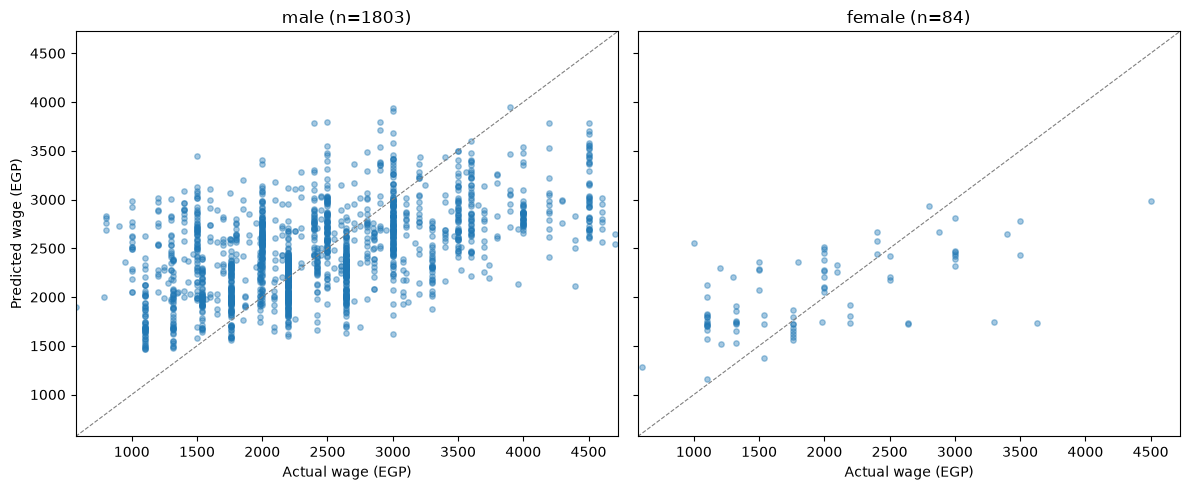

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, sex_label in zip(axes, ["male", "female"]):
    info = LAST_MODELS[sex_label]
    y_true, y_pred = info["y_test"], info["y_pred"]
    ax.scatter(y_true, y_pred, alpha=0.4, s=15)
    lims = [0.95 * min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max()) * 1.05]
    ax.plot(lims, lims, color="gray", linestyle="--", linewidth=0.8)
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_xlabel("Actual wage (EGP)")
    ax.set_title(f"{sex_label} (n={len(y_true)})")
axes[0].set_ylabel("Predicted wage (EGP)")
plt.tight_layout()
plt.show()


Best regression parameters: depth=6, learning_rate=0.075 

Best classfication parameters: depth=5, learning_rate=0.01

In [16]:
if "comparison_log" not in globals():
    comparison_log = []

_results, _gap, _ = run_once(RNG_SEED, iterations=5000, learning_rate=0.075, depth=6, early_stopping_rounds=200, use_best_model=True)
print(pd.DataFrame(_results).T)
print()
print("Gender gap (EGP/month), predicted vs. observed:", _gap)

_config_label = f"EMPSTAB={INCLUDE_EMPSTAB}, HRSWK_F={INCLUDE_HRSWK_FEMALE}, ZERO={ZERO_HANDLING!r}"
for _sex_label, _m in _results.items():
    comparison_log.append({"config": _config_label, **_m})
print(f"\nLogged this run as {_config_label!r} -- comparison_log has {len(comparison_log)} rows "
      f"({len(comparison_log)//2} configurations tried this session). See Section 10c to visualize."
      )

if "comparison_log_c" not in globals():
    comparison_log_c = []
    
_results_c, _gap_c, _ = run_once_classifier(RNG_SEED, iterations=5000, learning_rate=0.01, depth=5, early_stopping_rounds=200, use_best_model=True)
print(pd.DataFrame(_results_c).T)
print()
print("Gender gap (EGP/month), predicted vs. observed:", _gap)

_config_label = f"EMPSTAB={INCLUDE_EMPSTAB}, HRSWK_F={INCLUDE_HRSWK_FEMALE}, ZERO={ZERO_HANDLING!r}"
for _sex_label, _m in _results_c.items():
    comparison_log.append({"config": _config_label, **_m})
print(f"\nLogged this run as {_config_label!r} -- comparison_log has {len(comparison_log)} rows "
      f"({len(comparison_log)//2} configurations tried this session). See Section 10c to visualize."
      )


         label     n         mae        rmse        r2  spearman mean_pred_at_true_zero mean_pred_at_true_positive mean_actual_at_true_positive intensive_mae  \
male      male  1803  567.762314  763.157318  0.264783  0.504304                    NaN                2463.713103                   2458.87207    567.762314   
female  female    84  493.364445  616.165738  0.361723  0.584093                    NaN                 2051.02154                  1927.321411    493.364445   

       intensive_rmse intensive_r2  
male       763.157318     0.264783  
female     616.165738     0.361723  

Gender gap (EGP/month), predicted vs. observed: {}

Logged this run as "EMPSTAB=True, HRSWK_F=True, ZERO='drop_random'" -- comparison_log has 6 rows (3 configurations tried this session). See Section 10c to visualize.
         label     n  accuracy precision   recall        f1       auc    pr_auc   logloss pred_positive_rate actual_positive_rate
male      male  1970  0.943147  0.954814  0.98447  0.969

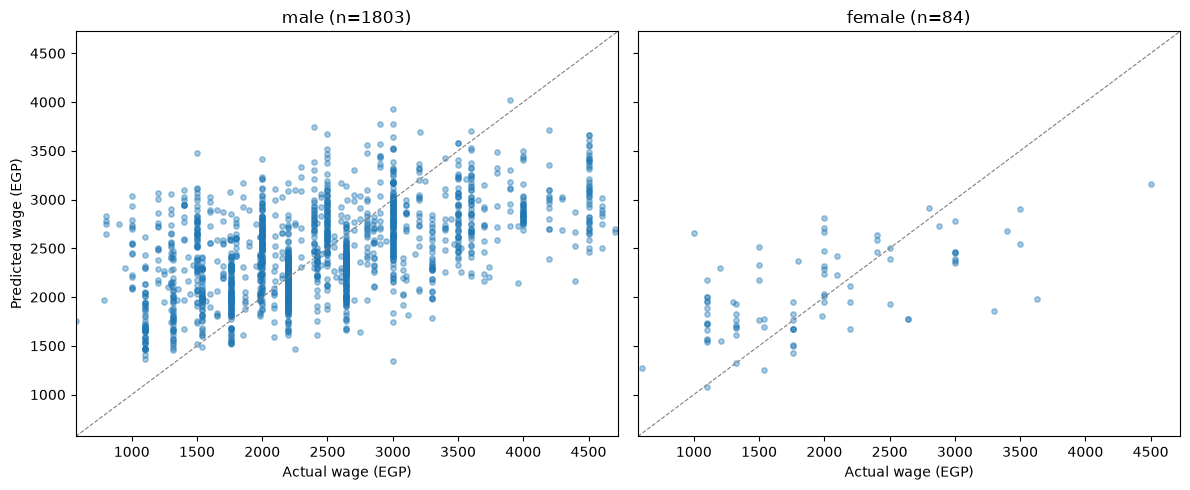

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, sex_label in zip(axes, ["male", "female"]):
    info = LAST_MODELS[sex_label]
    y_true, y_pred = info["y_test"], info["y_pred"]
    ax.scatter(y_true, y_pred, alpha=0.4, s=15)
    lims = [0.95 * min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max()) * 1.05]
    ax.plot(lims, lims, color="gray", linestyle="--", linewidth=0.8)
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_xlabel("Actual wage (EGP)")
    ax.set_title(f"{sex_label} (n={len(y_true)})")
axes[0].set_ylabel("Predicted wage (EGP)")
plt.tight_layout()
plt.show()


#### 10b. SHAP at the current settings

<div style="font-size: 10pt;">

Feature importance for the model trained in Section 10. Re-run Section 10 after a settings change, then re-run this cell.

</div>

=== male SHAP summary (EMPSTAB=True, HRSWK_F=True, ZERO='drop_random') ===


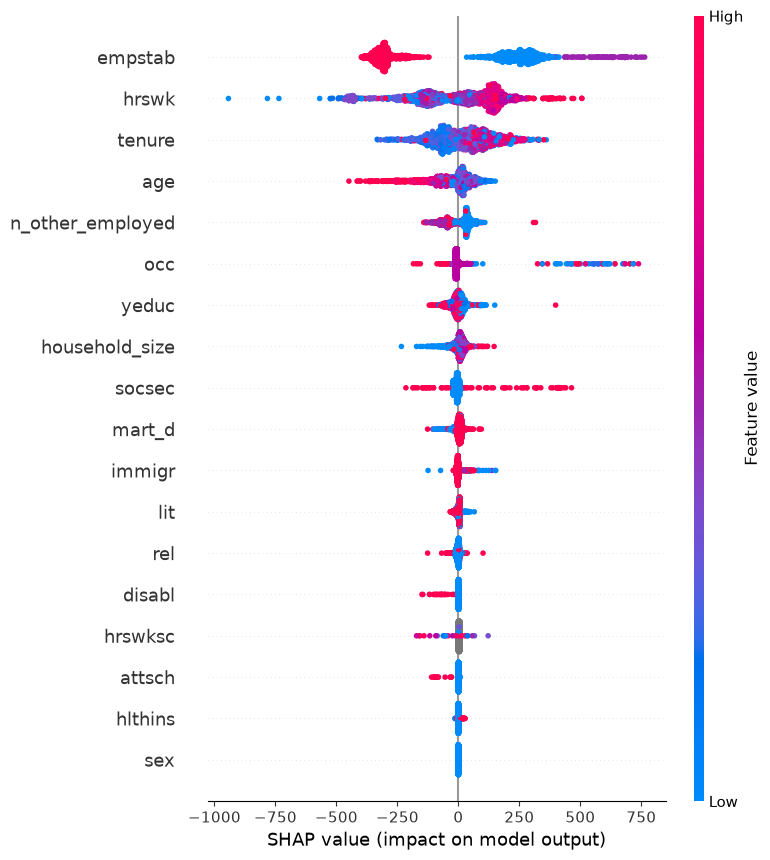

=== female SHAP summary (EMPSTAB=True, HRSWK_F=True, ZERO='drop_random') ===


/Users/hemert/projects/egypt-survey-ml/.venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1396: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


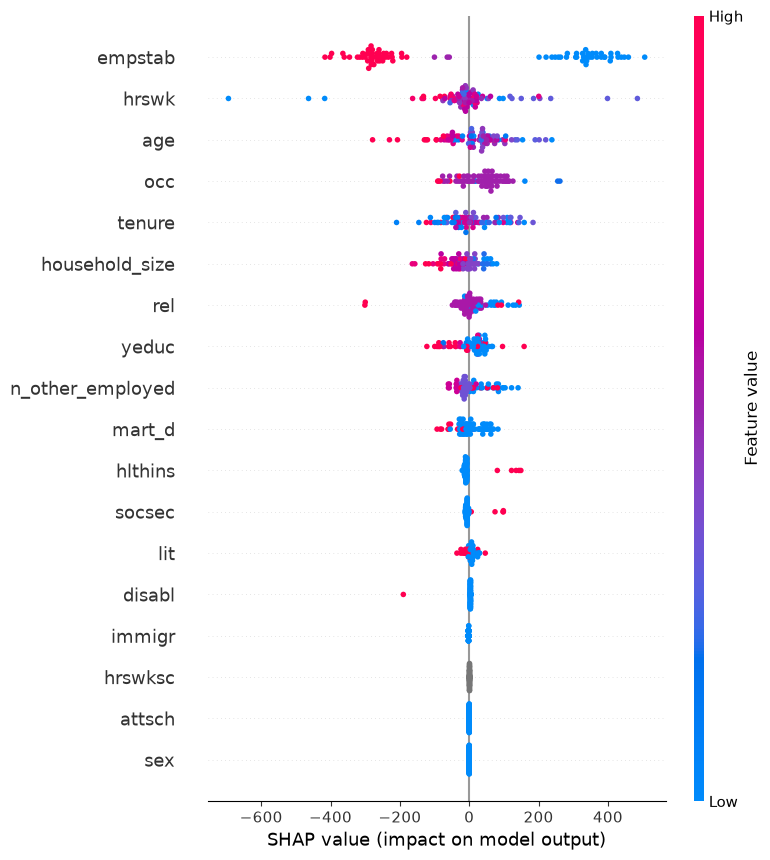

In [18]:
for _sex_label in ["male", "female"]:
    _info = LAST_MODELS[_sex_label]
    _explainer = shap.TreeExplainer(_info["model"])
    _shap_values = _explainer.shap_values(_info["X_test"])
    print(f"=== {_sex_label} SHAP summary ({_config_label}) ===")
    shap.summary_plot(_shap_values, _info["X_test"], show=True)
    # shap.dependence_plot("hrswk", _shap_values, _info["X_test"])

=== male SHAP summary (EMPSTAB=True, HRSWK_F=True, ZERO='drop_random') ===


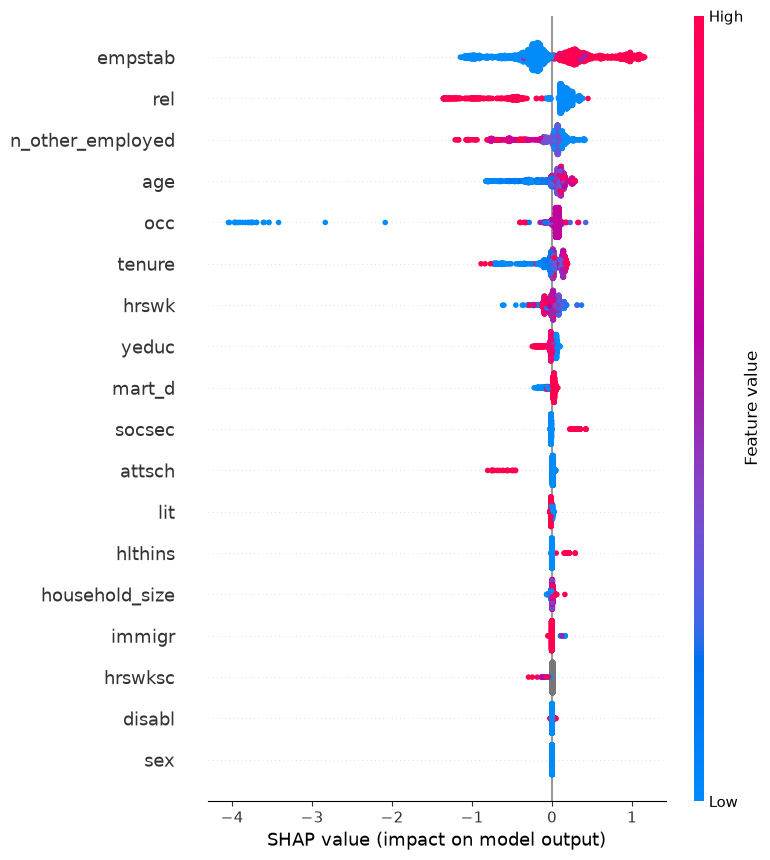

=== female SHAP summary (EMPSTAB=True, HRSWK_F=True, ZERO='drop_random') ===


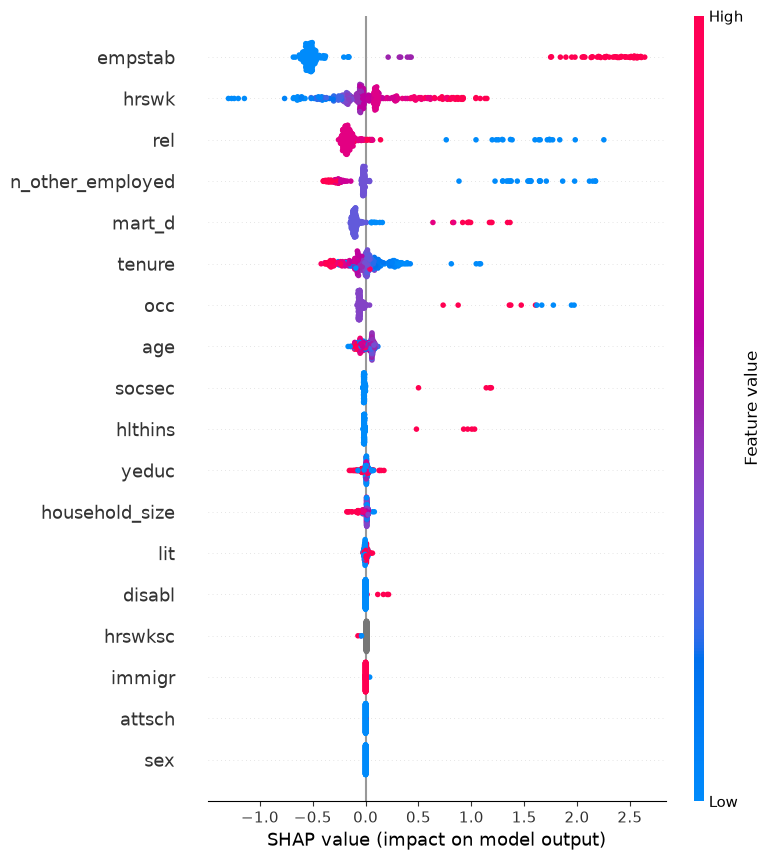

In [19]:
for _sex_label in ["male", "female"]:
    _info = LAST_MODELS_CLASSIFIER[_sex_label]
    _explainer = shap.TreeExplainer(_info["model"])
    _shap_values = _explainer.shap_values(_info["X_test"])
    print(f"=== {_sex_label} SHAP summary ({_config_label}) ===")
    shap.summary_plot(_shap_values, _info["X_test"], show=True)


#### 11. Repeated evaluation across command-unit draws

<div style="font-size: 10pt;">

Only the command-unit draw changes between repetitions; population, features and settings stay fixed. This isolates how much of the result comes from that randomness versus the model itself. Progress prints as it runs.

</div>

In [19]:
hp_reg_male_df = pd.read_csv(REPO_ROOT / 'models/hp_tuning/hp_outcome_regression_male.csv')
hp_reg_female_df = pd.read_csv(REPO_ROOT / 'models/hp_tuning/hp_outcome_regression_female.csv')
hp_cls_df = pd.read_csv(REPO_ROOT / 'models/hp_tuning/hp_outcome_classification.csv')

hp_parameters = {
    "male": hp_reg_male_df,
    "female": hp_reg_female_df,
}

In [20]:
import time
try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = lambda x, **kwargs: x  # progress bar is a nicety, not a dependency

records = []
all_runs = []
gap_runs = []
start_time = time.time()
PRINT_EVERY = max(1, N_REPS // 20)  # ~20 status lines total, regardless of N_REPS
MODEL_DIR = REPO_ROOT / 'models/hp-tuned/regressors'
MALE_MODELS = MODEL_DIR / 'male'
FEMALE_MODELS = MODEL_DIR / 'female'

MALE_MODELS.mkdir(exist_ok=True, parents=True)
FEMALE_MODELS.mkdir(exist_ok=True, parents=True)
results = {}
for sex_label in ["male", "female"]:
    hp_reg_df = hp_parameters[sex_label]
    for i, row in tqdm(hp_reg_df.iterrows(), desc="command-unit reassignment reps", total=len(hp_reg_df)):
        seed = int(row['seed'])
        depth = row['depth']
        lr = row['lr']
        
        res, gap, models = run_once(seed=seed, iterations=5000, learning_rate=lr, depth=depth, early_stopping_rounds=200, use_best_model=True, sex_label=sex_label)
        model = models[sex_label]['model']
        model_path = MODEL_DIR / sex_label / f"model_{i:03d}.cbm"
        model.save_model(model_path)
    
        results.setdefault(i, {})
        results[i][sex_label] = {
            "r2": res[sex_label]["r2"],
            "model_file": str(model_path),
            "seed": seed,
        }

        if len(results[i]) == 2:
            records.append({
                "rep": i,
                "seed": seed,
                "male_r2": results[i]["male"]["r2"],
                "female_r2": results[i]["female"]["r2"],
                "male_model_file": results[i]["male"]["model_file"],
                "female_model_file": results[i]["female"]["model_file"],
            })
        for sex_label, m in res.items():
            all_runs.append(m)
        gap_runs.append(gap)
    
        if (i + 1) % PRINT_EVERY == 0 or (i + 1) == N_REPS:
            elapsed = time.time() - start_time
            rate = elapsed / (i + 1)
            eta_min = rate * (N_REPS - (i + 1)) / 60
            running = pd.DataFrame(all_runs)
            male_r2 = running.loc[running["label"] == "male", "r2"].median()
            female_r2 = running.loc[running["label"] == "female", "r2"].median()
            print(f"[rep {i + 1}/{N_REPS}]  elapsed={elapsed/60:.1f} min  "
                  f"est. remaining={eta_min:.1f} min  "
                  f"running median R²: male={male_r2:.3f}  female={female_r2:.3f}")

metrics_df = pd.DataFrame(records)
metrics_df.to_csv(MODEL_DIR / "model_metrics.csv", index=False)

runs_df = pd.DataFrame(all_runs)
gaps_df = pd.DataFrame(gap_runs)

print(f"\n=== {N_REPS} repetitions, percentile summary ===\n")
for sex_label in ["male", "female"]:
    sub = runs_df[runs_df["label"] == sex_label]
    print(f"--- {sex_label} ---")
    print(sub[["mae", "rmse", "r2", "spearman"]].describe(percentiles=[0.05, 0.5, 0.95]).loc[["5%", "50%", "95%"]])
    print()

print("--- predicted vs. observed gender gap across repetitions ---")
print(gaps_df.describe(percentiles=[0.05, 0.5, 0.95]).loc[["5%", "50%", "95%"]])


command-unit reassignment reps:   0%|          | 0/100 [00:00<?, ?it/s]

[rep 5/100]  elapsed=0.2 min  est. remaining=4.1 min  running median R²: male=0.288  female=nan
[rep 10/100]  elapsed=0.4 min  est. remaining=3.6 min  running median R²: male=0.287  female=nan
[rep 15/100]  elapsed=0.6 min  est. remaining=3.3 min  running median R²: male=0.285  female=nan
[rep 20/100]  elapsed=0.8 min  est. remaining=3.1 min  running median R²: male=0.280  female=nan
[rep 25/100]  elapsed=1.0 min  est. remaining=3.0 min  running median R²: male=0.278  female=nan
[rep 30/100]  elapsed=1.2 min  est. remaining=2.9 min  running median R²: male=0.278  female=nan
[rep 35/100]  elapsed=1.4 min  est. remaining=2.7 min  running median R²: male=0.278  female=nan
[rep 40/100]  elapsed=1.6 min  est. remaining=2.5 min  running median R²: male=0.278  female=nan
[rep 45/100]  elapsed=1.8 min  est. remaining=2.2 min  running median R²: male=0.278  female=nan
[rep 50/100]  elapsed=2.0 min  est. remaining=2.0 min  running median R²: male=0.279  female=nan
[rep 55/100]  elapsed=2.2 min  

command-unit reassignment reps:   0%|          | 0/100 [00:00<?, ?it/s]

[rep 5/100]  elapsed=4.0 min  est. remaining=75.7 min  running median R²: male=0.283  female=0.219
[rep 10/100]  elapsed=4.0 min  est. remaining=36.2 min  running median R²: male=0.283  female=0.221
[rep 15/100]  elapsed=4.1 min  est. remaining=23.0 min  running median R²: male=0.283  female=0.219
[rep 20/100]  elapsed=4.1 min  est. remaining=16.3 min  running median R²: male=0.283  female=0.205
[rep 25/100]  elapsed=4.1 min  est. remaining=12.4 min  running median R²: male=0.283  female=0.201
[rep 30/100]  elapsed=4.2 min  est. remaining=9.7 min  running median R²: male=0.283  female=0.201
[rep 35/100]  elapsed=4.2 min  est. remaining=7.8 min  running median R²: male=0.283  female=0.201
[rep 40/100]  elapsed=4.3 min  est. remaining=6.4 min  running median R²: male=0.283  female=0.205
[rep 45/100]  elapsed=4.3 min  est. remaining=5.3 min  running median R²: male=0.283  female=0.205
[rep 50/100]  elapsed=4.3 min  est. remaining=4.3 min  running median R²: male=0.283  female=0.203
[rep 5

ValueError: Cannot describe a DataFrame without columns

In [22]:
import time
try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = lambda x, **kwargs: x  # progress bar is a nicety, not a dependency

records = []
all_runs = []
gap_runs = []
start_time = time.time()
PRINT_EVERY = max(1, N_REPS // 20)  # ~20 status lines total, regardless of N_REPS
MODEL_DIR = REPO_ROOT / 'models/hp-tuned/no-ribasim/classifiers'
MALE_MODELS = MODEL_DIR / 'male'
FEMALE_MODELS = MODEL_DIR / 'female'

MALE_MODELS.mkdir(exist_ok=True, parents=True)
FEMALE_MODELS.mkdir(exist_ok=True, parents=True)

for i, row in tqdm(hp_cls_df.iterrows(), desc="command-unit reassignment reps", total=len(hp_cls_df)):
    seed = int(row['seed'])
    depth = row['depth']
    lr = row['lr']
    
    res, gap, models = run_once_classifier(seed=seed, iterations=5000, learning_rate=lr, depth=depth, early_stopping_rounds=200, use_best_model=True)
    for sex_label in ["male", "female"]:
        model = models[sex_label]['model']
        model_path = MODEL_DIR / sex_label / f"model_{i:03d}.cbm"
        model.save_model(model_path)

    records.append({
        "rep": i,
        "seed": seed,
        "male_accuracy": res["male"]["accuracy"],
        "female_accuracy": res["female"]["accuracy"],
        "model_file": str(model_path),
    })
    for sex_label, m in res.items():
        all_runs.append(m)
    gap_runs.append(gap)

    if (i + 1) % PRINT_EVERY == 0 or (i + 1) == N_REPS:
        elapsed = time.time() - start_time
        rate = elapsed / (i + 1)
        eta_min = rate * (N_REPS - (i + 1)) / 60
        running = pd.DataFrame(all_runs)
        male_acc = running.loc[running["label"] == "male", "accuracy"].median()
        female_acc = running.loc[running["label"] == "female", "accuracy"].median()
        print(f"[rep {i + 1}/{N_REPS}]  elapsed={elapsed/60:.1f} min  "
              f"est. remaining={eta_min:.1f} min  "
              f"running median accuracy: male={male_r2:.3f}  female={female_r2:.3f}")

metrics_df = pd.DataFrame(records)
metrics_df.to_csv(MODEL_DIR / "model_metrics.csv", index=False)

runs_df = pd.DataFrame(all_runs)
gaps_df = pd.DataFrame(gap_runs)

print(f"\n=== {N_REPS} repetitions, percentile summary ===\n")
for sex_label in ["male", "female"]:
    sub = runs_df[runs_df["label"] == sex_label]
    print(f"--- {sex_label} ---")
    print(sub[["mae", "rmse", "r2", "spearman"]].describe(percentiles=[0.05, 0.5, 0.95]).loc[["5%", "50%", "95%"]])
    print()

print("--- predicted vs. observed gender gap across repetitions ---")
print(gaps_df.describe(percentiles=[0.05, 0.5, 0.95]).loc[["5%", "50%", "95%"]])


command-unit reassignment reps:   0%|          | 0/100 [00:00<?, ?it/s]

[rep 5/100]  elapsed=0.2 min  est. remaining=4.3 min  running median accuracy: male=0.093  female=0.055
[rep 10/100]  elapsed=0.5 min  est. remaining=4.2 min  running median accuracy: male=0.093  female=0.055
[rep 15/100]  elapsed=0.7 min  est. remaining=4.0 min  running median accuracy: male=0.093  female=0.055
[rep 20/100]  elapsed=1.0 min  est. remaining=3.9 min  running median accuracy: male=0.093  female=0.055
[rep 25/100]  elapsed=1.2 min  est. remaining=3.6 min  running median accuracy: male=0.093  female=0.055
[rep 30/100]  elapsed=1.5 min  est. remaining=3.5 min  running median accuracy: male=0.093  female=0.055
[rep 35/100]  elapsed=1.7 min  est. remaining=3.2 min  running median accuracy: male=0.093  female=0.055
[rep 40/100]  elapsed=2.0 min  est. remaining=2.9 min  running median accuracy: male=0.093  female=0.055
[rep 45/100]  elapsed=2.2 min  est. remaining=2.7 min  running median accuracy: male=0.093  female=0.055
[rep 50/100]  elapsed=2.4 min  est. remaining=2.4 min  r

KeyError: "None of [Index(['mae', 'rmse', 'r2', 'spearman'], dtype='str')] are in the [columns]"

#### 11b. Distribution across the 100 command-unit draws

<div style="font-size: 10pt;">

Box plots built from `runs_df` and `gaps_df` (both set in Section 11), showing the full spread behind the P5/P50/P95 numbers above, not just the three percentile points. Needs Section 11 to have run in this kernel session; if it prints a message asking you to re-run Section 11, that means the kernel was restarted since the last run and those two variables are gone from memory.

</div>

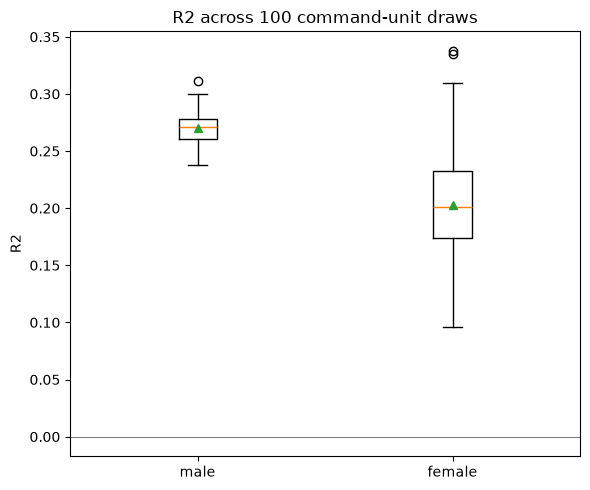

male: median=0.271  IQR=[0.261, 0.278]  min=0.238  max=0.311
female: median=0.201  IQR=[0.174, 0.232]  min=0.096  max=0.338


In [22]:
if "runs_df" not in globals():
    print("runs_df not found in memory -- re-run Section 11 first, then re-run this cell.")
else:
    fig, ax = plt.subplots(figsize=(6, 5))
    r2_by_sex = [runs_df.loc[runs_df["label"] == sex, "r2"].values for sex in ["male", "female"]]
    ax.boxplot(r2_by_sex, tick_labels=["male", "female"], showmeans=True)
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_title(f"R2 across {len(runs_df) // 2} command-unit draws")
    ax.set_ylabel("R2")
    plt.tight_layout()
    plt.show()

    for sex in ["male", "female"]:
        sub = runs_df.loc[runs_df["label"] == sex, "r2"]
        print(f"{sex}: median={sub.median():.3f}  IQR=[{sub.quantile(0.25):.3f}, {sub.quantile(0.75):.3f}]  "
              f"min={sub.min():.3f}  max={sub.max():.3f}")
